# LAB1 - Bài 14 (Online Retail, Bài 5a - Trang 45): Germany, min_sup = 5%, min_conf = 50%

**Họ tên:** Đinh Công Vinh Quang  
**MSSV:** 6451071061

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

HO_TEN, MSSV = "Đinh Công Vinh Quang", "6451071061"
print(f"{HO_TEN} - {MSSV}")
import time
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

Đinh Công Vinh Quang - 6451071061


In [2]:
# 1. Đọc dữ liệu
df = pd.read_excel("Online_Retail.xlsx")
print("Kích thước ban đầu:", df.shape)

# 2. Cắt ký tự thừa ở Description, xóa dòng không có InvoiceNo, đổi InvoiceNo về chuỗi
df["Description"] = df["Description"].str.strip()
df = df.dropna(axis=0, subset=["InvoiceNo"])
df["InvoiceNo"] = df["InvoiceNo"].astype("str")

# 3. Xóa hóa đơn tín dụng (InvoiceNo chứa 'C')
credit = df[df["InvoiceNo"].str.contains("C")]
df = df[~df["InvoiceNo"].str.contains("C")]
print("Số dòng hóa đơn tín dụng đã xóa:", len(credit), "| còn lại:", len(df))
# 5. Hóa đơn nước Anh, gom nhóm Quantity theo InvoiceNo và Description
def make_basket(data, country):
    return (data[data["Country"] == country]
            .groupby(["InvoiceNo", "Description"])["Quantity"].sum().unstack(fill_value=0))

# 7. Chuyển về hot/one-hot encoding: Quantity > 0 -> 1 (True), còn lại 0 (False)
def encode_units(x):
    return x > 0



Kích thước ban đầu: (541909, 8)


Số dòng hóa đơn tín dụng đã xóa: 9288 | còn lại: 532621


In [3]:
COUNTRY, MIN_SUP, MIN_CONF = "Germany", 0.05, 0.5
basket_sets = encode_units(make_basket(df, COUNTRY))
if "POSTAGE" in basket_sets.columns:
    basket_sets = basket_sets.drop(columns=["POSTAGE"])
print("Số hóa đơn:", basket_sets.shape[0], "| số mặt hàng:", basket_sets.shape[1])

Số hóa đơn: 457 | số mặt hàng: 1694


In [4]:
frequent_itemsets = apriori(basket_sets, min_support=MIN_SUP, use_colnames=True)
print("Số tập phổ biến (Apriori):", len(frequent_itemsets))
frequent_itemsets.sort_values("support", ascending=False).head(10)

Số tập phổ biến (Apriori): 59


,support,itemsets
35,0.245077,frozenset({ROUND SNACK BOXES SET OF4 WOODLAND})
34,0.157549,frozenset({ROUND SNACK BOXES SET OF 4 FRUITS})
24,0.137856,frozenset({PLASTERS IN TIN WOODLAND ANIMALS})
31,0.137856,frozenset({REGENCY CAKESTAND 3 TIER})
56,0.131291,"frozenset({ROUND SNACK BOXES SET OF4 WOODLAND,..."
48,0.126915,frozenset({WOODLAND CHARLOTTE BAG})
21,0.115974,frozenset({PLASTERS IN TIN CIRCUS PARADE})
22,0.107221,frozenset({PLASTERS IN TIN SPACEBOY})
0,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
44,0.102845,frozenset({SPACEBOY LUNCH BOX})


In [5]:
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=MIN_CONF)
rules["antecedents"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
rules["consequents"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
print("Số luật:", len(rules))
for _, r in rules.iterrows():
    print(f"{r['antecedents']}  =>  {r['consequents']}   (support={r['support']:.3f}, confidence={r['confidence']:.3f})")

Số luật: 8
PLASTERS IN TIN CIRCUS PARADE  =>  PLASTERS IN TIN WOODLAND ANIMALS   (support=0.068, confidence=0.585)
PLASTERS IN TIN SPACEBOY  =>  PLASTERS IN TIN WOODLAND ANIMALS   (support=0.061, confidence=0.571)
PLASTERS IN TIN WOODLAND ANIMALS  =>  ROUND SNACK BOXES SET OF4 WOODLAND   (support=0.074, confidence=0.540)
RED RETROSPOT CHARLOTTE BAG  =>  WOODLAND CHARLOTTE BAG   (support=0.059, confidence=0.844)
ROUND SNACK BOXES SET OF4 WOODLAND  =>  ROUND SNACK BOXES SET OF 4 FRUITS   (support=0.131, confidence=0.536)
ROUND SNACK BOXES SET OF 4 FRUITS  =>  ROUND SNACK BOXES SET OF4 WOODLAND   (support=0.131, confidence=0.833)
SPACEBOY LUNCH BOX  =>  ROUND SNACK BOXES SET OF4 WOODLAND   (support=0.070, confidence=0.681)
WOODLAND CHARLOTTE BAG  =>  ROUND SNACK BOXES SET OF4 WOODLAND   (support=0.063, confidence=0.500)


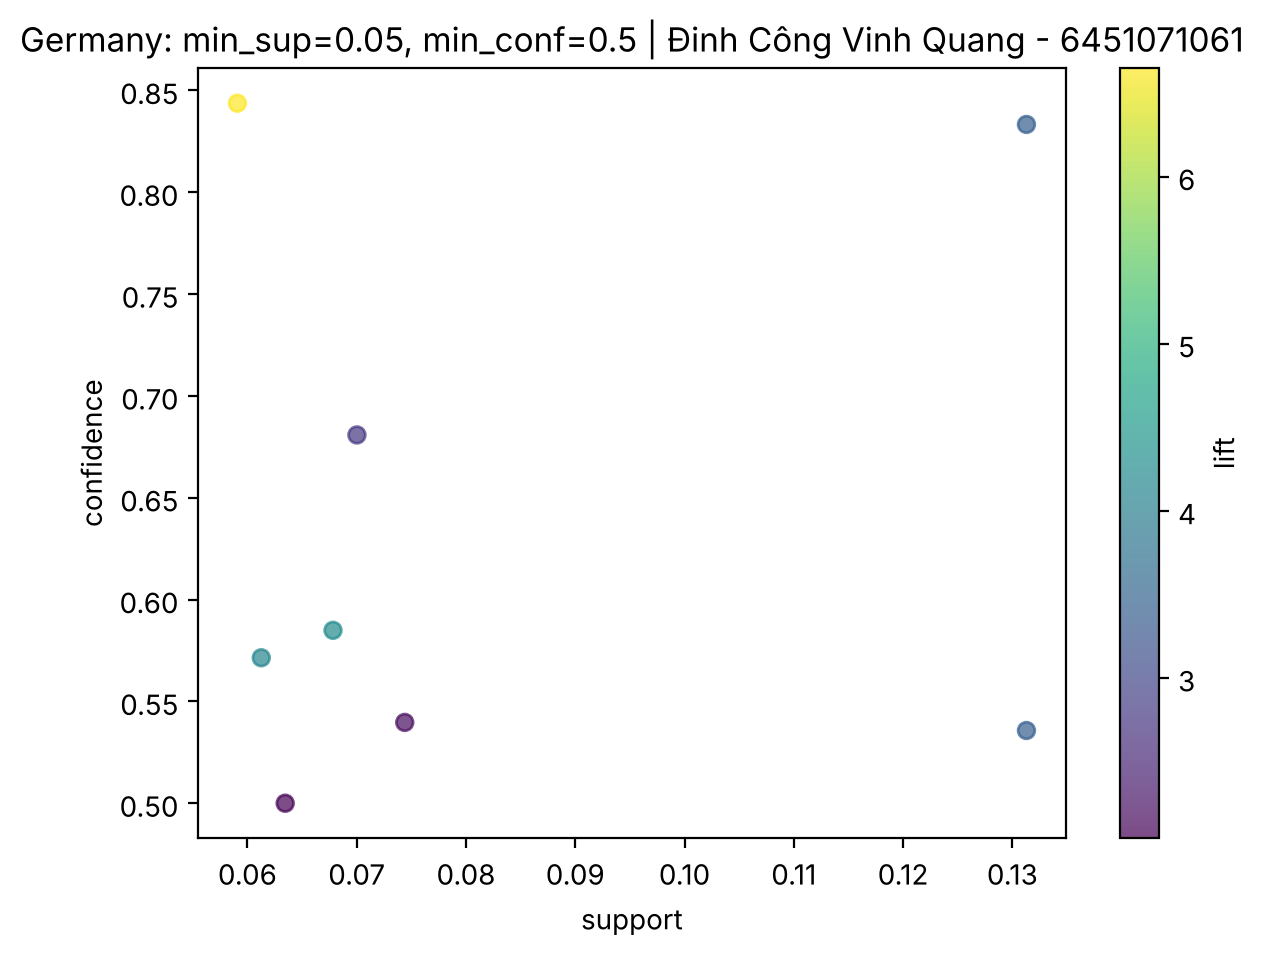

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(rules["support"], rules["confidence"], alpha=0.7, c=rules["lift"], cmap="viridis")
plt.colorbar(label="lift")
plt.xlabel("support"); plt.ylabel("confidence")
plt.title(f"{COUNTRY}: min_sup={MIN_SUP}, min_conf={MIN_CONF} | {HO_TEN} - {MSSV}")
plt.show()

In [7]:
def compare(basket_sets, min_sup, min_conf):
    t = time.perf_counter(); ap = apriori(basket_sets, min_support=min_sup, use_colnames=True); t_ap = time.perf_counter() - t
    t = time.perf_counter(); fp = fpgrowth(basket_sets, min_support=min_sup, use_colnames=True); t_fp = time.perf_counter() - t
    same = ({(frozenset(a), round(s, 6)) for a, s in zip(ap["itemsets"], ap["support"])} ==
            {(frozenset(a), round(s, 6)) for a, s in zip(fp["itemsets"], fp["support"])})
    r_ap = association_rules(ap, metric="confidence", min_threshold=min_conf) if len(ap) else ap
    r_fp = association_rules(fp, metric="confidence", min_threshold=min_conf) if len(fp) else fp
    print(f"Apriori  : {len(ap)} tập phổ biến, {len(r_ap)} luật, {t_ap:.2f}s")
    print(f"FP-Growth: {len(fp)} tập phổ biến, {len(r_fp)} luật, {t_fp:.2f}s")
    print("Hai thuật toán cho cùng tập phổ biến và support:", same)
    return ap, r_ap
_ = compare(basket_sets, MIN_SUP, MIN_CONF)

Apriori  : 59 tập phổ biến, 8 luật, 0.00s
FP-Growth: 59 tập phổ biến, 8 luật, 0.01s
Hai thuật toán cho cùng tập phổ biến và support: True
